# Geolocated Environments

In [13]:
from pathlib import Path
import geopandas as gpd
from shapely.geometry import Point, LineString
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
import contextily as cx

import imp_act

# plt.rcParams.update({
#     "font.size": 8,
#     "font.family": "serif",
#     "font.serif": ["Times New Roman"],
#     "axes.titlesize": 8,
#     "axes.labelsize": 8,
#     "xtick.labelsize": 7,
#     "ytick.labelsize": 7,
#     "legend.fontsize": 7,
# })

In [14]:
# Example values: "Cologne-v1", "CologneBonnDusseldorf-v1", "FR", "DE", ...
ENV_NAME = "DE"
env = imp_act.make(ENV_NAME)
graph = env.graph

In [15]:
# Build GeoDataFrames (WGS84 -> Web Mercator).
gdf_nodes = gpd.GeoDataFrame(
    {
        "id": [v["id"] for v in graph.vs],
        "geometry": [
            Point(float(v["position_x"]), float(v["position_y"])) for v in graph.vs
        ],
    },
    crs="EPSG:4326",
)

edges = []
for e in graph.es:
    v1 = graph.vs[e.source]
    v2 = graph.vs[e.target]

    if "volume" in e.attributes():
        volume = e["volume"]
    elif "base_volume" in e.attributes():
        volume = e["base_volume"]
    else:
        volume = 0.0
    travel_time = e["travel_time"] if "travel_time" in e.attributes() else None
    if "road_edge" in e.attributes():
        edge_capacity = min(seg.capacity for seg in e["road_edge"].segments)
    else:
        edge_capacity = None
    volume_pct = (volume / edge_capacity * 100) if edge_capacity else 0.0

    edges.append(
        {
            "u": v1["id"],
            "v": v2["id"],
            "volume": volume,
            "travel_time": travel_time,
            "volume_pct": volume_pct,
            "geometry": LineString(
                [
                    (float(v1["position_x"]), float(v1["position_y"])),
                    (float(v2["position_x"]), float(v2["position_y"])),
                ]
            ),
        }
    )

gdf_edges = gpd.GeoDataFrame(edges, crs="EPSG:4326")
gdf_nodes_3857 = gdf_nodes.to_crs(epsg=3857)
gdf_edges_3857 = gdf_edges.to_crs(epsg=3857)

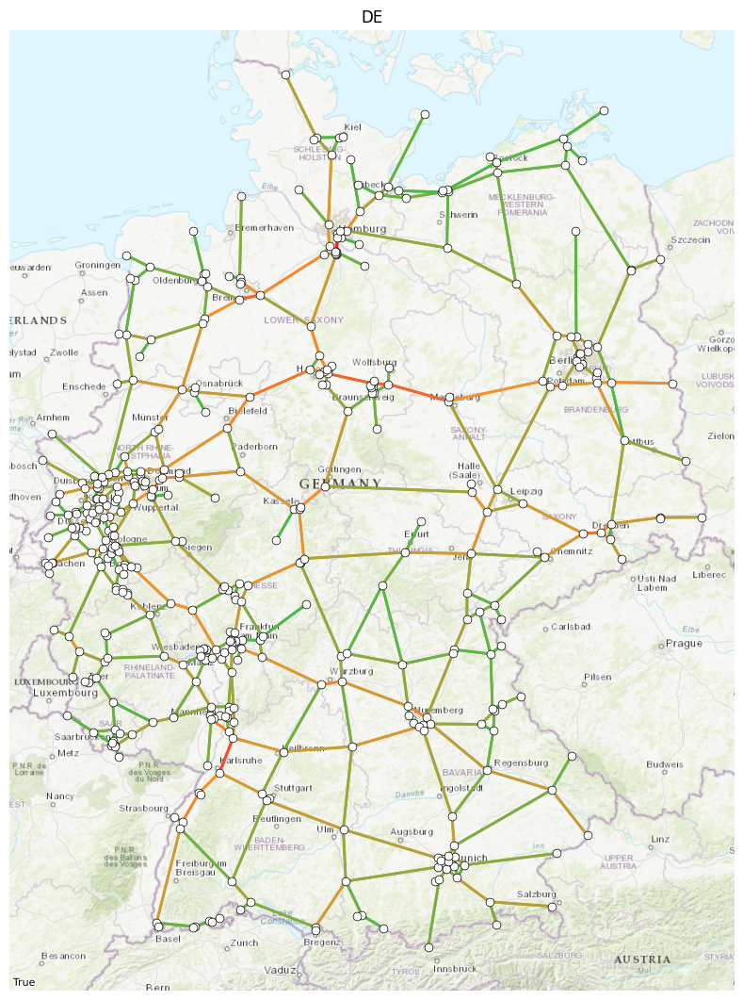

In [16]:
# Styling
vpct = gdf_edges_3857["volume_pct"].fillna(0)
vmin = float(vpct.min())
vmax = float(vpct.max())
if vmin == vmax:
    vmax = vmin + 1.0

traffic_cmap = LinearSegmentedColormap.from_list(
    "traffic_signal", ["#4fb848", "#f7922d", "#ed2024"]
)
norm_v = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
gdf_edges_3857["edge_color"] = [traffic_cmap(norm_v(v)) for v in vpct]

# Plot
minx, miny, maxx, maxy = gdf_edges_3857.total_bounds
width_m = maxx - minx
height_m = maxy - miny
fig_width = 10
fig_height = max(3.5, fig_width * (height_m / width_m))

fig, ax = plt.subplots(1, 1, figsize=(fig_width, fig_height))

gdf_edges_3857.plot(
    ax=ax,
    linewidth=2,
    color=gdf_edges_3857["edge_color"],
    linestyle="solid",
    alpha=1.0,
    zorder=1,
)

gdf_nodes_3857.plot(
    ax=ax,
    marker="o",
    markersize=40,
    facecolor="white",
    edgecolor="black",
    linewidth=0.5,
    zorder=3,
)

cx.add_basemap(
    ax,
    source=cx.providers.Esri.WorldTopoMap,
    alpha=1.0,
    zorder=0,
    attribution=True,
)

ax.set_axis_off()
ax.set_title(ENV_NAME)

out_path = Path.cwd() / f"{ENV_NAME}.svg"
# plt.savefig(out_path, format="svg", dpi=300)
plt.show()

# Environment Cards


In [17]:
from imp_act import make
from imp_act.environments.registry import Registry
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import contextily as cx
from pathlib import Path
import math
import re
from functools import lru_cache

import geopandas as gpd
from shapely.geometry import Point, LineString
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

In [18]:
def get_yaml_path(env_name: str) -> Path:
    _, params = reg[env_name]
    return Path(params["filename"])


@lru_cache(maxsize=None)
def get_env_cached(name: str):
    """Create/load an environment once per name (LRU cached)."""
    return make(name)


@lru_cache(maxsize=None)
def get_geodata_cached(env_name: str):
    env = get_env_cached(env_name)
    graph = env.graph

    xs = [float(v["position_x"]) for v in graph.vs]
    ys = [float(v["position_y"]) for v in graph.vs]
    looks_geographic = (
        min(xs) >= -180.0 and max(xs) <= 180.0 and min(ys) >= -90.0 and max(ys) <= 90.0
    )

    gdf_nodes = gpd.GeoDataFrame(
        {
            "id": [v["id"] for v in graph.vs],
            "geometry": [
                Point(float(v["position_x"]), float(v["position_y"])) for v in graph.vs
            ],
        },
        crs="EPSG:4326",
    )

    edges = []
    for e in graph.es:
        v1 = graph.vs[e.source]
        v2 = graph.vs[e.target]

        if "volume" in e.attributes():
            volume = e["volume"]
        elif "base_volume" in e.attributes():
            volume = e["base_volume"]
        else:
            volume = 0.0

        if "road_edge" in e.attributes():
            edge_capacity = min(seg.capacity for seg in e["road_edge"].segments)
        else:
            edge_capacity = None
        volume_pct = (volume / edge_capacity * 100) if edge_capacity else 0.0

        edges.append(
            {
                "u": v1["id"],
                "v": v2["id"],
                "volume": volume,
                "volume_pct": volume_pct,
                "geometry": LineString(
                    [
                        (float(v1["position_x"]), float(v1["position_y"])),
                        (float(v2["position_x"]), float(v2["position_y"])),
                    ]
                ),
            }
        )

    gdf_edges = gpd.GeoDataFrame(edges, crs="EPSG:4326")
    gdf_nodes_3857 = gdf_nodes.to_crs(epsg=3857)
    gdf_edges_3857 = gdf_edges.to_crs(epsg=3857)
    return gdf_nodes_3857, gdf_edges_3857, looks_geographic


# Basemap caching
TILE_CACHE_DIR = Path("./.tile_cache").resolve()
TILE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
cx.set_cache_dir(str(TILE_CACHE_DIR))


def prefetch_basemap(env_names, zoom=6, provider=cx.providers.Esri.WorldTopoMap):
    """Download basemap tiles for each env bounding box into the cache."""
    for name in env_names:
        gdf_nodes_3857, gdf_edges_3857, looks_geographic = get_geodata_cached(name)
        if not looks_geographic:
            continue
        minx, miny, maxx, maxy = gdf_edges_3857.total_bounds
        # bounds2img fetches and caches tiles
        try:
            cx.bounds2img(minx, miny, maxx, maxy, zoom=zoom, source=provider)
        except Exception as exc:
            print(f"Basemap prefetch failed for {name}: {exc}")


# Country code to pretty name mapping (ISO2)
ISO2_TO_NAME = {
    "AT": "Austria",
    "BE": "Belgium",
    "BG": "Bulgaria",
    "BY": "Belarus",
    "CH": "Switzerland",
    "CZ": "Czechia",
    "DE": "Germany",
    "DK": "Denmark",
    "EE": "Estonia",
    "ES": "Spain",
    "FI": "Finland",
    "FR": "France",
    "GR": "Greece",
    "HR": "Croatia",
    "HU": "Hungary",
    "IE": "Ireland",
    "IT": "Italy",
    "LT": "Lithuania",
    "LU": "Luxembourg",
    "LV": "Latvia",
    "MK": "North Macedonia",
    "NL": "Netherlands",
    "NO": "Norway",
    "PL": "Poland",
    "PT": "Portugal",
    "RO": "Romania",
    "RS": "Serbia",
    "RU": "Russia",
    "SE": "Sweden",
    "SI": "Slovenia",
    "SK": "Slovakia",
    "TR": "Turkey",
    "UA": "Ukraine",
    "UK": "United Kingdom",
}


def get_pretty_title(env_name: str) -> str:
    p = get_yaml_path(env_name)
    parent = p.parent.name
    stem = p.stem
    # Prefer full country name if parent folder is an ISO2 code we've mapped
    pretty = ISO2_TO_NAME.get(parent)
    if pretty is None and stem == parent and len(parent) == 2 and parent.isupper():
        # Fallback title-case if an unmapped 2-letter code appears
        pretty = parent.title()
    return pretty if pretty else env_name


# Include base '<dir>/<dir>.yaml' and any '*-v1.yaml'; exclude explicit '-jax'.
# Collect all registered environments; dedupe by YAML file so JAX variants collapse to one.
def is_candidate(name: str) -> bool:
    p = get_yaml_path(name)
    stem = p.stem
    parent = p.parent.name
    # Exclude unconstrained/budget variants
    if (
        stem.endswith("-unconstrained")
        or stem.endswith("-only-maintenance")
        or stem.endswith("-moderate-budget")
        or stem.endswith("-critical-budget")
    ):
        return False
    # Keep '-v1' stems and base country (filename equals its folder)
    return stem.endswith("-v1") or (stem == parent)


# Registry helper: resolve backing YAML path for a registered env name
reg = Registry()
candidates = [n for n in reg if is_candidate(n)]
# Deduplicate by YAML file name, preferring non-"-jax" names when both exist
unique_by_yaml = {}
for n in candidates:
    y = get_yaml_path(n).name
    if y not in unique_by_yaml:
        unique_by_yaml[y] = n
    else:
        # Prefer non-jax name
        if unique_by_yaml[y].endswith("-jax") and not n.endswith("-jax"):
            unique_by_yaml[y] = n
env_names = sorted(unique_by_yaml.values())

# -------------------------------------------
# Build env_df once using cached environments
# -------------------------------------------
_rows = []
for _name in env_names:
    _env = get_env_cached(_name)
    g = _env.graph
    _nodes = g.vcount()
    _edges = g.ecount()
    _density = float(g.density()) if _nodes > 1 else 0.0
    _avg_deg = float(np.mean(g.degree())) if _nodes else 0.0
    _comps = (
        len(g.connected_components(mode="weak"))
        if g.is_directed()
        else len(g.connected_components())
    )
    _trips = len(getattr(_env, "trips", []))
    _y = get_yaml_path(_name)
    segment_lengths = np.array(_env.graph.es["distance"])
    _rows.append(
        {
            "env_name": _name,
            "display_name": get_pretty_title(_name),
            "yaml_name": _y.name,
            "country_code": _y.parent.name,
            "nodes": _nodes,
            "edges": _edges,
            "density": _density,
            "avg_degree": _avg_deg,
            "connected_components": _comps,
            "trips": _trips,
            "budget_amount": getattr(
                _env,
                "budget_amount",
                _env.config["maintenance"].get("budget_amount", np.nan),
            ),
            "budget_interval": getattr(
                _env,
                "budget_renewal_interval",
                _env.config["maintenance"].get("budget_renewal_interval", np.nan),
            ),
            "reward_factor": _env.config["traffic"].get(
                "travel_time_reward_factor", np.nan
            ),
            "segment_length_mean": float(np.mean(segment_lengths)),
            "segment_length_max": float(np.max(segment_lengths)),
            "segment_length_cov": float(
                np.std(segment_lengths)
                / np.mean(segment_lengths)  # coefficient of variation
            ),
        }
    )
# global dataFrame with environment info for plotting
env_df = pd.DataFrame(_rows)

# Prefetch basemaps once to warm the cache for all cards.
PREFETCH_ZOOM = 8
prefetch_basemap(env_names, zoom=PREFETCH_ZOOM)

### Plotting function

In [19]:
def fmt_millions(x):
    try:
        m = float(x) / 1e6
    except Exception:
        return str(x)
    if m >= 100:
        return f"{int(round(m))}M"
    if m >= 10:
        return f"{m:.0f}M"
    return f"{m:.1f}M"


def plot_environment_summary(env_name: str, env_df: pd.DataFrame, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 3))

    gdf_nodes_3857, gdf_edges_3857, looks_geographic = get_geodata_cached(env_name)

    vpct = gdf_edges_3857["volume_pct"].fillna(0)
    vmin = float(vpct.min())
    vmax = float(vpct.max())
    if vmin == vmax:
        vmax = vmin + 1.0

    traffic_cmap = LinearSegmentedColormap.from_list(
        "traffic_signal", ["#4fb848", "#f7922d", "#ed2024"]
    )
    norm_v = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    edge_colors = [traffic_cmap(norm_v(v)) for v in vpct]

    ax.set_aspect("equal", adjustable="datalim")
    ax.set_axis_off()

    minx, miny, maxx, maxy = gdf_edges_3857.total_bounds
    ax.set_xlim(minx, maxx)
    ax.set_ylim(miny, maxy)

    if looks_geographic:
        cx.add_basemap(
            ax,
            source=cx.providers.Esri.WorldTopoMap,
            zorder=0,
            attribution=False,
            reset_extent=False,
        )

    gdf_edges_3857.plot(
        ax=ax,
        linewidth=1.2,
        color=edge_colors,
        linestyle="solid",
        zorder=1,
    )
    gdf_nodes_3857.plot(
        ax=ax,
        marker="o",
        markersize=12,
        facecolor="white",
        edgecolor="black",
        linewidth=0.4,
        zorder=2,
    )

    row = env_df.loc[env_df["env_name"] == env_name]
    if row.empty:
        raise ValueError(f"plot_environment_summary: env_df has no row for {env_name}")
    row = row.iloc[0]

    stats = {
        "nodes": f"nodes: {int(row.nodes)}",
        "edges": f"edges: {int(row.edges)}",
        "density": f"density: {float(row.density):.3f}",
        "avg_degree": f"avg_deg: {float(row.avg_degree):.2f}",
        "connected_components": f"connected_components: {int(row.connected_components)}",
        "segment_length_cov": f"segment_lengths_cov: {float(row.segment_length_cov):.3f}",
    }

    info = "\n".join(
        [
            "$\mathbf{GENERAL}$",
            f"Reward factor: {row.reward_factor}",
            f"Budget: {fmt_millions(row.budget_amount)}",
            f"Trips: {int(row.trips)}",
            "",
            "$\mathbf{GRAPH\ STATS}$",
            *stats.values(),
        ]
    )

    ax.text(
        -0.02,
        0.98,
        info,
        transform=ax.transAxes,
        clip_on=False,
        va="top",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.4),
    )

    ax.set_title(
        rf"{get_pretty_title(env_name)} ({row.yaml_name})",
        fontsize=12,
        fontweight="bold",
        pad=10,
    )
    return ax

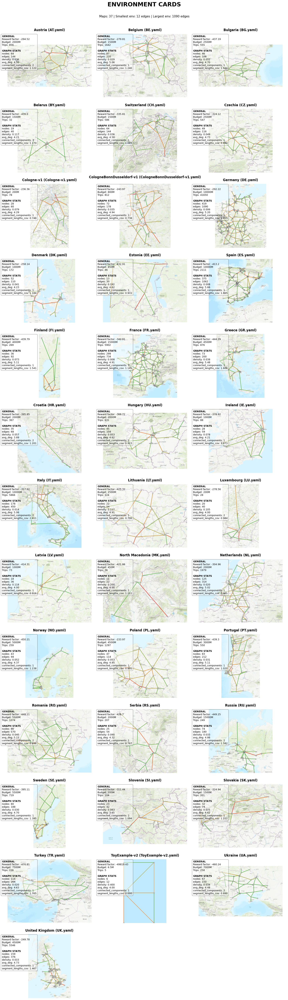

In [20]:
sizes_series = env_df.set_index("env_name").loc[env_names, "edges"]
_sizes = sizes_series.tolist()
N = len(env_names)
cols = 3
rows = math.ceil(N / cols) if N else 1
fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 4))
fig.suptitle("ENVIRONMENT CARDS", fontsize=22, fontweight="bold", y=0.995)
fig.text(
    0.5,
    0.982,
    f"Maps: {N} | Smallest env: {min(_sizes)} edges | Largest env: {max(_sizes)} edges",
    ha="center",
    va="top",
    fontsize=11,
)
axes = np.array(axes).reshape(rows, cols) if N > 1 else np.array([[axes]])

for idx, name in enumerate(env_names):
    r, c = divmod(idx, cols)
    plot_environment_summary(name, env_df, ax=axes[r, c])

# Hide any leftover axes
for blank in range(N, rows * cols):
    r, c = divmod(blank, cols)
    axes[r, c].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.98])

# Optional: save the figure
save_fig = True  # set True to save
if save_fig:
    save_dir = Path("./output")
    save_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_dir / "environment_cards.pdf", bbox_inches="tight", dpi=300)
plt.show()

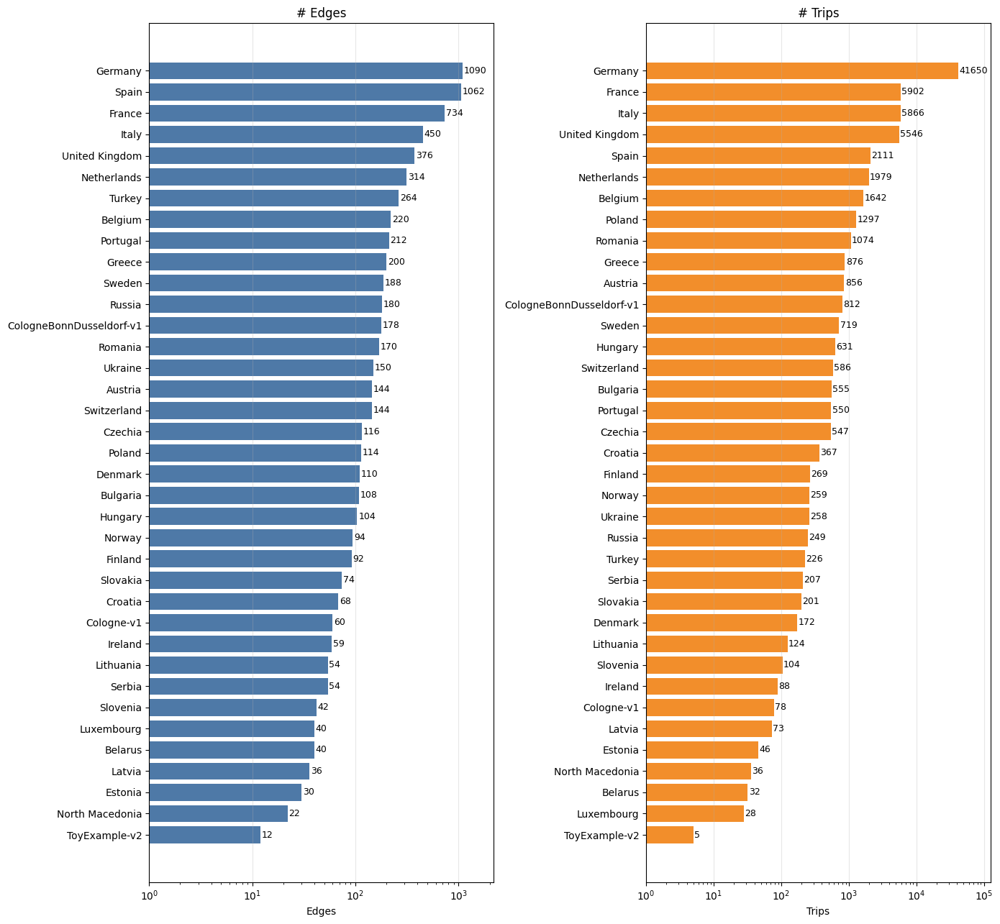

In [21]:
# Bar plots of environment sizes: #edges and #trips
_df = env_df.copy()

_edges_sorted = _df.sort_values("edges")[["display_name", "edges"]]
_trips_sorted = _df.sort_values("trips")[["display_name", "trips"]]

names_edges = _edges_sorted["display_name"].tolist()
vals_edges = _edges_sorted["edges"].tolist()

names_trips = _trips_sorted["display_name"].tolist()
vals_trips = _trips_sorted["trips"].tolist()

h = max(4, 0.35 * len(_df))
fig2, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, h))

bars1 = ax1.barh(names_edges, vals_edges, color="#4e79a7")
ax1.set_title("# Edges", fontsize=12)
ax1.set_xlabel("Edges")
ax1.set_xscale("log")

bars2 = ax2.barh(names_trips, vals_trips, color="#f28e2b")
ax2.set_title("# Trips", fontsize=12)
ax2.set_xlabel("Trips")
ax2.set_xscale("log")

# Always place labels just outside the bars (right side)
max_e = max(vals_edges) if len(vals_edges) else 1
max_t = max(vals_trips) if len(vals_trips) else 1
ax1.set_xlim(left=1, right=max_e * 2.0)
ax2.set_xlim(left=1, right=max_t * 3)
xmax1 = ax1.get_xlim()[1]
xmax2 = ax2.get_xlim()[1]
for rect, v in zip(bars1, vals_edges):
    y = rect.get_y() + rect.get_height() / 2
    ax1.text(
        min(v * 1.03, xmax1 * 0.95),
        y,
        f"{int(v)}",
        va="center",
        ha="left",
        color="black",
        fontsize=9,
    )
for rect, v in zip(bars2, vals_trips):
    y = rect.get_y() + rect.get_height() / 2
    ax2.text(
        min(v * 1.03, xmax2 * 0.95),
        y,
        f"{int(v)}",
        va="center",
        ha="left",
        color="black",
        fontsize=9,
    )

for ax in (ax1, ax2):
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

# Optional: save the figure
save_fig = True  # set True to save
if save_fig:
    save_dir = Path("./output")
    save_dir.mkdir(parents=True, exist_ok=True)
    fig2.savefig(save_dir / "environment_sizes.pdf", bbox_inches="tight")

plt.show()